# Ordering books by color

People who shelve books by color want neighbors that look alike, so the shelf reads as one gradient. The usual advice is to sort by hue. This notebook asks how good that is, and what the best order is.

The plan:

1. Treat each color as a point, so that "look alike" becomes a distance.
2. Show why sorting by hue fails on grays, browns and pastels.
3. Find the best order exactly: a shortest path through the colors.
4. Compare five quicker methods on a large shelf, and score them two ways: total color jump, and how well each keeps a color's nearest colors near it.

The code lives in the `maps` package; this notebook calls it.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from maps import colors, draw, paths, shelf, study
from maps.data import css_shelf

plt.rcParams["figure.dpi"] = 80

## A shelf of twelve books

Twelve spines, in the colors of twelve CSS named colors, chosen to include the colors that give hue sorting trouble: four grays from black to white, three browns, two pastels, and four strong colors. Here they are in the order they came in.

lightpink silver peachpuff saddlebrown sienna navy black white tan crimson orange dimgray


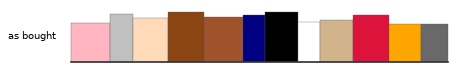

In [2]:
names = study.HAND
hexes = study.hand_hexes()
as_bought = [int(i) for i in np.random.default_rng(0).permutation(len(names))]
draw.shelves(hexes, {"as bought": as_bought}, width=6.5)
print(" ".join(names[i] for i in as_bought))

## Vocabulary

- A **color** is a point in [Oklab](https://bottosson.github.io/posts/oklab/), Ottosson's perceptual color space: L is lightness, a runs green to red, b runs blue to yellow. Distances in Oklab track how different two colors look much better than distances in sRGB.
- An **ordering** is a permutation of the books, left to right.
- A **jump** is the Oklab distance between two books standing side by side, and the **total jump** of an ordering is the sum of its jumps. The best ordering has the least total jump: a **shortest Hamiltonian path** with free ends.

Oklab's own test values pin the conversion down; the package's tests check all four rows of Ottosson's table. Here are a few of the twelve colors as points:

In [3]:
lab = colors.oklab(hexes)
dist = colors.distances(lab)
for i in (0, 1, 4, 8, 9):
    L, a, b = lab[i]
    print(f"{names[i]:12} L {L:.3f}  a {a:+.3f}  b {b:+.3f}")
print(f"\njump from orange to tan: {dist[8, 6]:.3f};  orange to crimson: {dist[8, 10]:.3f}")

black        L 0.000  a +0.000  b +0.000
dimgray      L 0.521  a +0.000  b +0.000
saddlebrown  L 0.471  a +0.071  b +0.087
orange       L 0.793  a +0.057  b +0.161
lightpink    L 0.847  a +0.085  b +0.014

jump from orange to tan: 0.108;  orange to crimson: 0.282


## Sorting by hue

A color picker describes a color by hue, saturation and value (HSV). Sorting by hue, ties broken by value, is what most guides suggest. *Before running the next cell, guess where the four grays go.*

In [4]:
hsv = colors.hsv(hexes)
order = shelf.hsv_hue(hexes)
for i in order:
    h, s, v = hsv[i]
    print(f"{names[i]:12} hue {360 * h:5.1f}°  saturation {s:.2f}  value {v:.2f}")

white        hue   0.0°  saturation 0.00  value 1.00
silver       hue   0.0°  saturation 0.00  value 0.75
dimgray      hue   0.0°  saturation 0.00  value 0.41
black        hue   0.0°  saturation 0.00  value 0.00
sienna       hue  19.3°  saturation 0.72  value 0.63
saddlebrown  hue  25.0°  saturation 0.86  value 0.55
peachpuff    hue  28.3°  saturation 0.27  value 1.00
tan          hue  34.3°  saturation 0.33  value 0.82
orange       hue  38.8°  saturation 1.00  value 1.00
navy         hue 240.0°  saturation 1.00  value 0.50
crimson      hue 348.0°  saturation 0.91  value 0.86
lightpink    hue 351.0°  saturation 0.29  value 1.00


Three things go wrong, each visible in that table.

- **Grays have no hue**, and HSV reports 0°, the hue of red. All four land at the red end of the shelf, in one block, next to whatever reds there are.
- **Browns are dark oranges.** Sienna and saddle brown have hues of 19° and 25°, between red and orange, so they sit beside bright orange and peach although they look nothing alike.
- **Pastels keep their hue.** Light pink (351°) stands next to crimson (348°); the hue sort sees one color where the eye sees two.

Sorting by Oklab's hue angle, which is closer to perceived hue, moves the grays (their hue is now whatever rounding error says) but does not fix any of the three. A third common recipe sorts along a Hilbert curve through the RGB cube, a path that visits every cell of the cube by unit steps.

hue (HSV)      total jump 3.674


hue (Oklab)    total jump 3.571
Hilbert curve  total jump 2.714


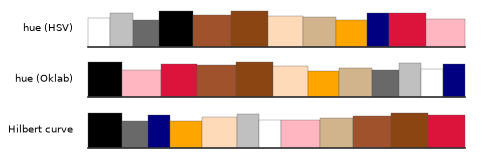

In [5]:
orders = {
    "hue (HSV)": shelf.hsv_hue(hexes),
    "hue (Oklab)": shelf.oklch_hue(hexes),
    "Hilbert curve": shelf.hilbert(hexes),
}
draw.shelves(hexes, orders, width=6.5)
for label, o in orders.items():
    print(f"{label:14} total jump {paths.total_jump(o, dist):.3f}")

## The shortest shelf, exactly

The best ordering is a traveling-salesman path. For a few books, try every ordering. A path and its reverse are the same shelf, so `brute_force_path` keeps only orderings whose first book is below its last: 9!/2 = 181,440 orderings for nine books.

In [6]:
timings = {}
start = time.perf_counter()
brute = paths.brute_force_path(dist[:9, :9])
timings["brute force, 9 books"] = time.perf_counter() - start
print(f"brute force, 9 books: {brute[0]:.6f}")
print(f"Held-Karp,   9 books: {paths.held_karp_path(dist[:9, :9])[0]:.6f}")

brute force, 9 books: 1.379293
Held-Karp,   9 books: 1.379293


Held and Karp's dynamic program does better than trying orderings. `best[S, j]` is the shortest path that visits exactly the set of books S and ends at book j. It is 0 for a single book, and otherwise the best over the book i visited just before j:

`best[S, j] = min over i in S - {j} of best[S - {j}, i] + dist(i, j)`.

There are 2ⁿ sets and n ends, so the time is O(2ⁿ n²) instead of n!. It agrees with brute force on nine books above, and on every random case in the tests. Twelve books take well under a second:

shortest total jump 1.710


hue (HSV)      total jump 3.674  ratio to shortest 2.15
hue (Oklab)    total jump 3.571  ratio to shortest 2.09
Hilbert curve  total jump 2.714  ratio to shortest 1.59
shortest       total jump 1.710  ratio to shortest 1.00


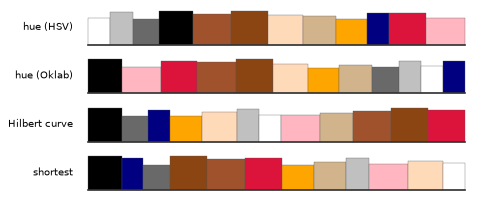

In [7]:
start = time.perf_counter()
best_length, best_order = paths.held_karp_path(dist)
best_order = paths.canonical(best_order)
timings["Held-Karp, 12 books"] = time.perf_counter() - start
print(f"shortest total jump {best_length:.3f}")
orders["shortest"] = best_order
draw.shelves(hexes, orders, width=6.5)
for label, o in orders.items():
    print(f"{label:14} total jump {paths.total_jump(o, dist):.3f}  ratio to shortest {paths.total_jump(o, dist) / best_length:.2f}")

The shortest shelf runs black, navy, dim gray, the browns, crimson, orange, tan, silver, the pastels, white: dark to light, with the strong colors in the middle. A hue sort costs 2.1 times the total jump of the shortest shelf here, and the Hilbert curve 1.6 times.

## All 139 CSS colors

The CSS named colors are a larger shelf with every kind of trouble: 139 distinct colors (148 names), many grays, browns, pinks and near-whites. Held-Karp needs 2¹³⁹ sets, so the exact answer comes from an integer program instead. `exact_path` adds a dummy book at distance 0 from every book, which turns the open path into a closed tour; it asks each book for two shelf neighbors, solves with HiGHS, and whenever the answer splits into several loops, forbids each loop and solves again. When one loop remains, it is a tour of least length, and HiGHS was asked to prove optimality with no gap.

Four quicker methods join the hue sorts:

- **greedy + 2-opt**: from each starting book, walk to the nearest unplaced book; then reverse any stretch of the shelf whose reversal shortens it; keep the best of the 139 starts.
- **1D SOM**: a self-organizing map whose units form a line, one unit per book, trained in Oklab (Kohonen 1982; the last notebook in this series covers SOMs). Books are sorted by their unit.
- **1D t-SNE**: t-SNE with one output dimension (van der Maaten and Hinton 2008; covered in the third notebook). Books are sorted by their coordinate.
- **shortest**: the integer program. It takes the longest, about a minute here.

In [8]:
css_names, css_hexes = css_shelf()
css_dist = colors.distances(colors.oklab(css_hexes))
css_orders = {}
for name, method in shelf.METHODS.items():
    start = time.perf_counter()
    css_orders[name] = method(css_hexes)
    timings[f"{name}, 139 books"] = time.perf_counter() - start
print("the integer program's ordering is a permutation:", sorted(css_orders["shortest"]) == list(range(139)))

the integer program's ordering is a permutation: True


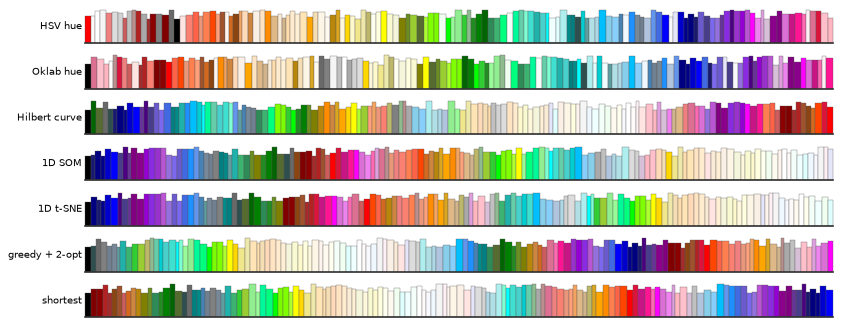

In [9]:
fig = draw.shelves(css_hexes, css_orders, width=11)

## Two scores

Total jump measures the shelf's links one at a time. A reader of the shelf also cares whether each color's nearest colors stand near it. Venna and Kaski's rank scores measure that. For each book i and a neighborhood size k:

- **Trustworthiness** T(k) penalizes books among i's k nearest on the shelf that are not among its k nearest in color, by how far down i's color ranking they are.
- **Continuity** C(k) penalizes books among i's k nearest in color that are not among its k nearest on the shelf, by how far down the shelf ranking they are.

Both are 1 when every k-neighborhood survives. On a shelf, a book has two neighbors at each distance, one on each side; as Venna and Kaski did for maps with ties, the best and the worst orders of the tied books are both scored, and the two are averaged.

In [10]:
css_scores = {name: shelf.score(css_hexes, order) for name, order in css_orders.items()}
print(f"{'':15} {'jump':>6} {'max jump':>8} {'T(2)':>6} {'C(2)':>6} {'T(5)':>6} {'C(5)':>6}")
for name, s in css_scores.items():
    print(f"{name:15} {s['jump']:6.2f} {s['max_jump']:8.3f} {s['T2']:6.3f} {s['C2']:6.3f} {s['T5']:6.3f} {s['C5']:6.3f}")

                  jump max jump   T(2)   C(2)   T(5)   C(5)
HSV hue          24.89    0.940  0.759  0.833  0.747  0.815
Oklab hue        26.68    0.692  0.727  0.840  0.725  0.834
Hilbert curve    12.51    0.461  0.944  0.885  0.914  0.849
1D SOM            8.98    0.322  0.987  0.961  0.980  0.948
1D t-SNE          9.26    0.330  0.983  0.971  0.972  0.964
greedy + 2-opt    8.34    0.405  0.991  0.935  0.973  0.890
shortest          8.13    0.407  0.993  0.961  0.978  0.908


What the table says:

- Hue sorts cost 3.1 and 3.3 times the shortest shelf's total jump (24.9 and 26.7 against 8.13). The Hilbert curve costs 1.5 times as much as the shortest shelf.
- Greedy + 2-opt comes within 2.6% of the shortest, and the 1D SOM and 1D t-SNE within 10% and 14%.
- The shortest shelf is the most trustworthy at k = 2, but not the most continuous: at k = 5 its continuity (0.908) is below the SOM's and t-SNE's (0.948 and 0.964). A shortest path visits each region of color space once and leaves it by its cheapest exit, so colors that are close but visited at different times end up far apart. The SOM and t-SNE are trained to keep neighborhoods, and they pay for it with longer jumps. Which shelf looks best is a matter of what one looks at: smooth steps, or similar colors kept together.

The shortest shelf's largest single jump (0.407) is larger than the SOM's and t-SNE's (0.322 and 0.330): the shortest path saves on its many small jumps and accepts a few big ones.

## Many small shelves

One shelf is one instance. Draw 100 shelves of 10 random CSS colors (seeds 0 to 99), find each one's shortest ordering with Held-Karp, and score every method on every shelf. *Excess* is a method's total jump over the shortest, minus 1.

In [11]:
start = time.perf_counter()
bench = study.benchmark_section()
timings["100 shelves of 10, every method"] = time.perf_counter() - start
print(f"{'':15} {'mean excess':>11} {'max excess':>10} {'solved':>6} {'T(2)':>6} {'C(2)':>6}")
for name, r in bench.items():
    print(f"{name:15} {r['mean_excess']:11.1%} {r['max_excess']:10.1%} {r['solved']:6.0%} {r['T2']:6.3f} {r['C2']:6.3f}")

                mean excess max excess solved   T(2)   C(2)
HSV hue               57.3%     158.8%     0%  0.661  0.657
Oklab hue             56.8%     157.3%     0%  0.659  0.667
Hilbert curve         32.7%      80.7%     0%  0.735  0.729
1D SOM                 2.5%      18.1%    35%  0.909  0.909
1D t-SNE              20.9%      58.5%     3%  0.817  0.837
greedy + 2-opt         0.1%       4.2%    91%  0.916  0.903
shortest               0.0%       0.0%   100%  0.915  0.900


On ten books, greedy + 2-opt finds the shortest shelf on most of the 100 shelves, and is never far from it. Hue sorts cost 57% more than the shortest, on average. The 1D t-SNE does worse on ten books than on 139: in one dimension, points cannot pass each other, so an early wrong order can stay. With the paper's learning rate of 100, ten points fly hundreds of units apart and the order barely improves; the package uses 10 for that reason.

## Variations and open questions

- **Other distances.** CIEDE2000 instead of Oklab distance would change the shortest shelf a little; whether it changes which method wins is open.
- **A circle.** A shelf with its ends joined (books on a round table) is a closed tour; `exact_path` already solves one, before it drops the dummy book.
- **Lightness first.** Many color-ordered shelves are sorted dark to light within hue bands; that is a sort by two keys, and it could be scored the same way.
- **Real spines.** A spine has more than one color. Using the dominant color of each spine, or a distance between color histograms, is the natural next step.

## Timings

Seconds on the machine that saved this notebook (one core of a shared server). CI does not compare this cell's output.

In [12]:
for what, seconds in timings.items():
    print(f"{what:32} {seconds:6.1f} s")

brute force, 9 books                1.2 s
Held-Karp, 12 books                 0.2 s
HSV hue, 139 books                  0.0 s
Oklab hue, 139 books                0.0 s
Hilbert curve, 139 books            0.0 s
1D SOM, 139 books                   1.4 s
1D t-SNE, 139 books                 0.7 s
greedy + 2-opt, 139 books          11.6 s
shortest, 139 books                45.5 s
100 shelves of 10, every method    18.9 s


## The numbers the README quotes

`maps/results/maps.json` holds the numbers above, written by `python -m maps.study`. This cell compares the runs of this notebook with the committed file.

In [13]:
stored = study.stored()
assert study.same(study.rounded(study.hand_section()), stored["hand"])
assert study.same(study.rounded({n: {**s, "order": css_orders[n]} for n, s in css_scores.items()}), stored["css"])
assert study.same(study.rounded(bench), stored["benchmark"])
print("hand, css and benchmark sections match maps/results/maps.json")

hand, css and benchmark sections match maps/results/maps.json
